In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv(
    '/kaggle/input/datasets/shivamb/netflix-shows/netflix_titles.csv'
)

# Display first 5 rows
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
df.describe(include='all')

# Missing values
df.isnull().sum()

Dataset Shape: (8807, 12)

Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

**Missing value percentage analysis**

In [4]:
# Calculate missing values
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
director,2634,29.908028
country,831,9.435676
cast,825,9.367549
date_added,10,0.113546
rating,4,0.045418
duration,3,0.034064
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
release_year,0,0.000000


**Check duplicate records**

In [5]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [6]:
# Check duplicate show IDs
duplicate_ids = df['show_id'].duplicated().sum()

print("Duplicate Show IDs:", duplicate_ids)

Duplicate Show IDs: 0


**Create a copy of the original dataset**

In [7]:
# Create a copy of original dataset
df_clean = df.copy()

# Check dataset shape
print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (8807, 12)
Working Dataset: (8807, 12)


**Remove unnecessary spaces**

In [8]:
# Select all text columns
text_columns = df_clean.select_dtypes(
    include=['object']
).columns

# Remove leading and trailing spaces
for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Extra spaces removed successfully!")

Extra spaces removed successfully!


**Convert date_added into datetime**

In [9]:
# Convert date_added to datetime
df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    errors='coerce'
)

# Check data type
print(df_clean['date_added'].dtype)

datetime64[ns]


**Handle duration column**

In [10]:
# Extract numeric duration
df_clean['duration_value'] = pd.to_numeric(
    df_clean['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Extract duration unit
df_clean['duration_unit'] = df_clean['duration'].str.extract(
    r'([A-Za-z]+)'
)

# Display results
df_clean[
    ['type', 'duration', 'duration_value', 'duration_unit']
].head(10)

,type,duration,duration_value,duration_unit
0,Movie,90 min,90.0,min
1,TV Show,2 Seasons,2.0,Seasons
2,TV Show,1 Season,1.0,Season
3,TV Show,1 Season,1.0,Season
4,TV Show,2 Seasons,2.0,Seasons
5,TV Show,1 Season,1.0,Season
6,Movie,91 min,91.0,min
7,Movie,125 min,125.0,min
8,TV Show,9 Seasons,9.0,Seasons
9,Movie,104 min,104.0,min


**Investigate missing duration records**

In [11]:
# Find records with missing duration
missing_duration = df_clean[
    df_clean['duration'].isnull()
]

missing_duration[
    ['show_id', 'type', 'title', 'rating', 'duration']
]

,show_id,type,title,rating,duration
5541,s5542,Movie,Louis C.K. 2017,74 min,NaN
5794,s5795,Movie,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,66 min,NaN


**Check and handle duplicate records**

In [12]:
# Count duplicate records
print(
    "Duplicate Rows:",
    df_clean.duplicated().sum()
)

Duplicate Rows: 0


**Check final data types**

In [13]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   show_id         8807 non-null   object        
 1   type            8807 non-null   object        
 2   title           8807 non-null   object        
 3   director        6173 non-null   object        
 4   cast            7982 non-null   object        
 5   country         7976 non-null   object        
 6   date_added      8797 non-null   datetime64[ns]
 7   release_year    8807 non-null   int64         
 8   rating          8803 non-null   object        
 9   duration        8804 non-null   object        
 10  listed_in       8807 non-null   object        
 11  description     8807 non-null   object        
 12  duration_value  8804 non-null   float64       
 13  duration_unit   8804 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(11)
m

**Final cleaning validation**

In [14]:
# Final missing value check
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nFinal Dataset Shape:")
print(df_clean.shape)

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nFirst 5 Cleaned Records:")
display(df_clean.head())

Missing Values After Cleaning:
show_id              0
type                 0
title                0
director          2634
cast               825
country            831
date_added          10
release_year         0
rating               4
duration             3
listed_in            0
description          0
duration_value       3
duration_unit        3
dtype: int64

Final Dataset Shape:
(8807, 14)

Duplicate Rows:
0

First 5 Cleaned Records:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,min
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,Seasons
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,Season
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,Season
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,Seasons


**How many Movies and TV Shows are available on Netflix?**

In [15]:
# Count Movies and TV Shows

content_type = df_clean['type'].value_counts()

print(content_type)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


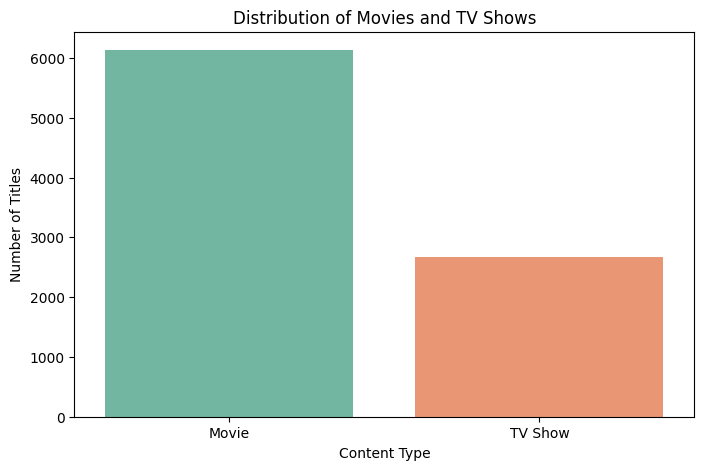

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='type',
    hue='type',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Movies and TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.show()

In [17]:
content_percentage = (
    df_clean['type'].value_counts(normalize=True) * 100
)

print(content_percentage.round(2))

type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


**What are the most common content ratings?**

In [18]:
# Count content ratings
rating_counts = df_clean['rating'].value_counts()

print(rating_counts)

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


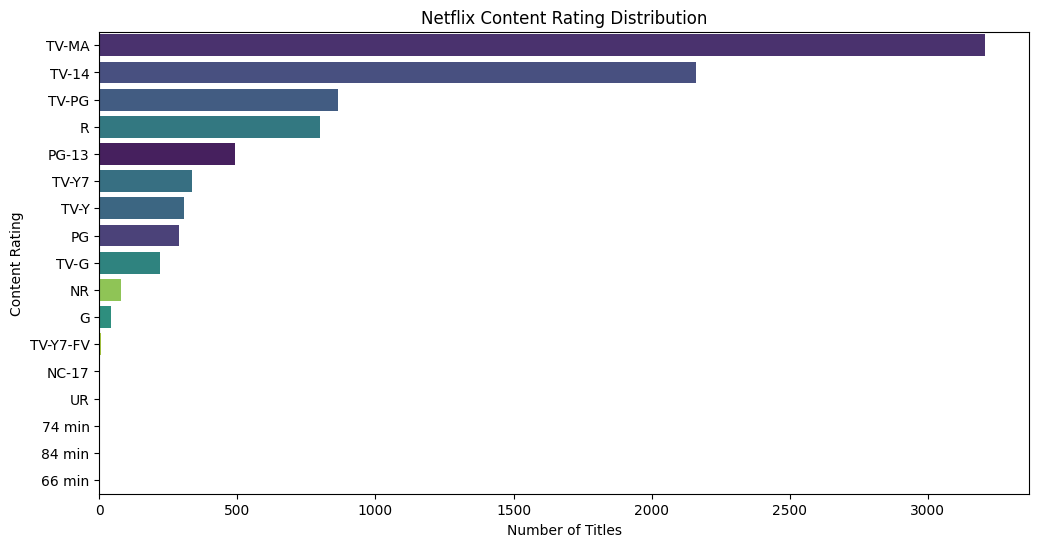

In [19]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    y='rating',
    order=df_clean['rating'].value_counts().index,
    hue='rating',
    palette='viridis',
    legend=False
)

plt.title('Netflix Content Rating Distribution')
plt.xlabel('Number of Titles')
plt.ylabel('Content Rating')

plt.show()

**Which release years have the highest number of titles?**

In [20]:
# Count titles by release year
release_year_counts = (
    df_clean['release_year']
    .value_counts()
    .sort_values(ascending=False)
)

print(release_year_counts.head(15))

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
2010     194
2011     185
2009     152
2008     136
2006      96
Name: count, dtype: int64


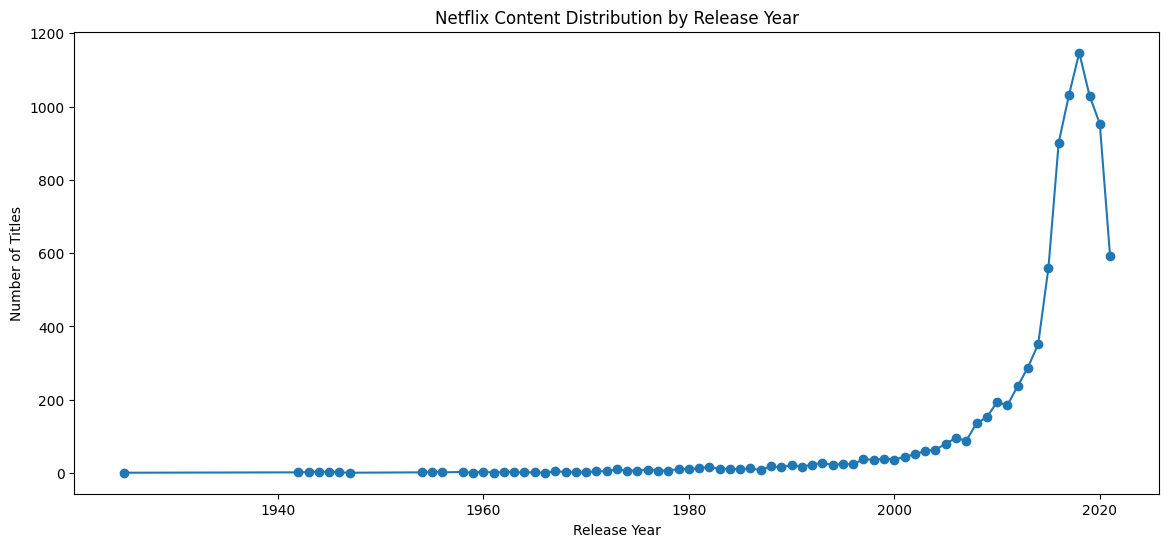

In [21]:
plt.figure(figsize=(14, 6))

yearly_counts = df_clean['release_year'].value_counts().sort_index()

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker='o'
)

plt.title('Netflix Content Distribution by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

**What is the distribution of movie durations?**

In [22]:
# Filter movie records
movies = df_clean[
    df_clean['type'] == 'Movie'
].copy()

# Select movie durations in minutes
movie_duration = movies[
    movies['duration_unit'] == 'min'
]['duration_value']

# Statistical summary
movie_duration.describe()

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64

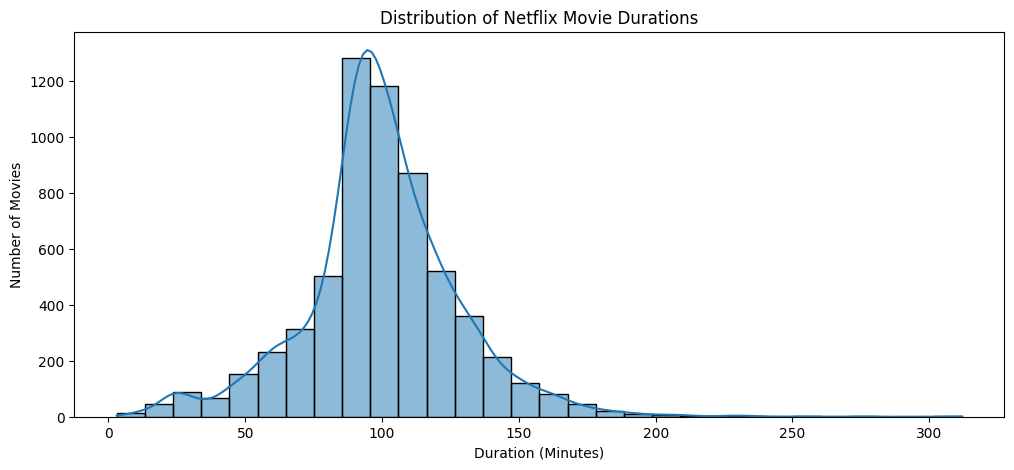

In [23]:
plt.figure(figsize=(12, 5))

sns.histplot(
    movie_duration.dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Netflix Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')

plt.show()

**How many seasons do Netflix TV Shows have?**

In [24]:
# Filter TV Shows
tv_shows = df_clean[
    df_clean['type'] == 'TV Show'
].copy()

# Extract season counts
seasons = tv_shows[
    tv_shows['duration_unit'].str.lower() == 'seasons'
]['duration_value']

# Statistical summary
seasons.describe()

count    883.000000
mean       3.318233
std        1.998178
min        2.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       17.000000
Name: duration_value, dtype: float64

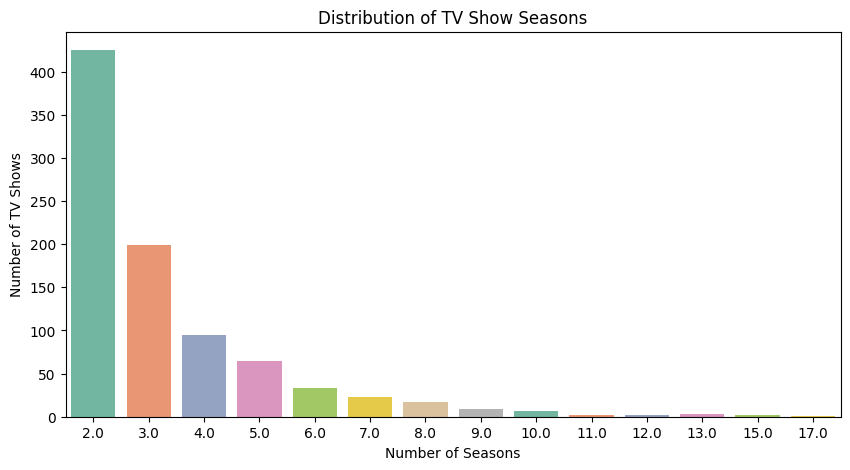

In [25]:
plt.figure(figsize=(10, 5))

sns.countplot(
    x=seasons.dropna(),
    hue=seasons.dropna(),
    palette='Set2',
    legend=False
)

plt.title('Distribution of TV Show Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')

plt.show()

**How has the number of Movies and TV Shows changed over the years?**

In [26]:
# Group by release year and content type

yearly_content = (
    df_clean.groupby(['release_year', 'type'])
    .size()
    .reset_index(name='total_titles')
)

# Display latest records
yearly_content.tail(10)

,release_year,type,total_titles
109,2017,Movie,767
110,2017,TV Show,265
111,2018,Movie,767
112,2018,TV Show,380
113,2019,Movie,633
114,2019,TV Show,397
115,2020,Movie,517
116,2020,TV Show,436
117,2021,Movie,277
118,2021,TV Show,315


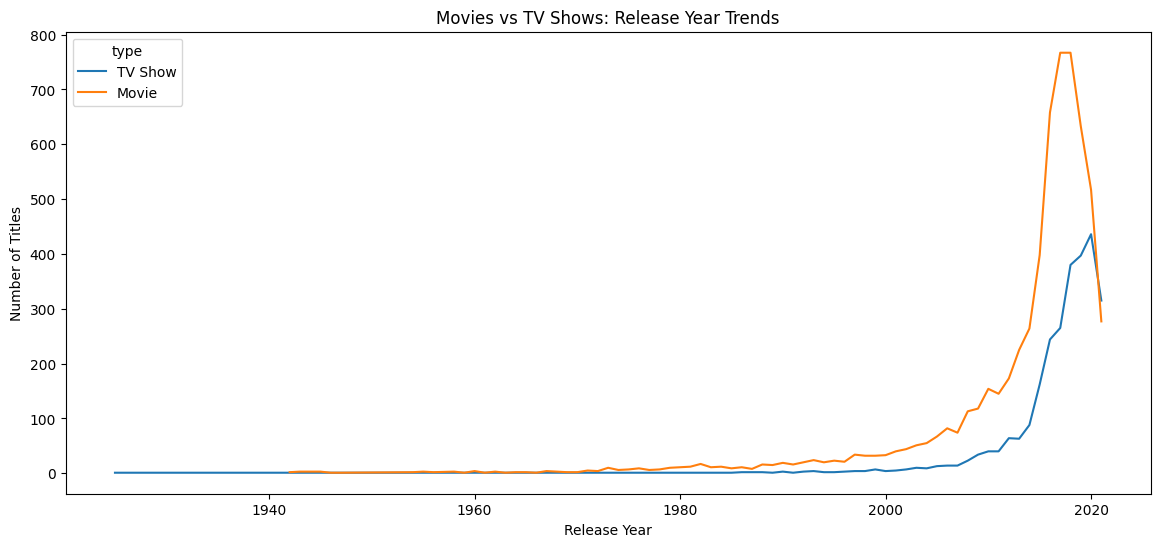

In [27]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_content,
    x='release_year',
    y='total_titles',
    hue='type'
)

plt.title('Movies vs TV Shows: Release Year Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

**Which content ratings are most common for Movies and TV Shows?**

In [28]:
rating_type = pd.crosstab(
    df_clean['rating'],
    df_clean['type']
)

rating_type

type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


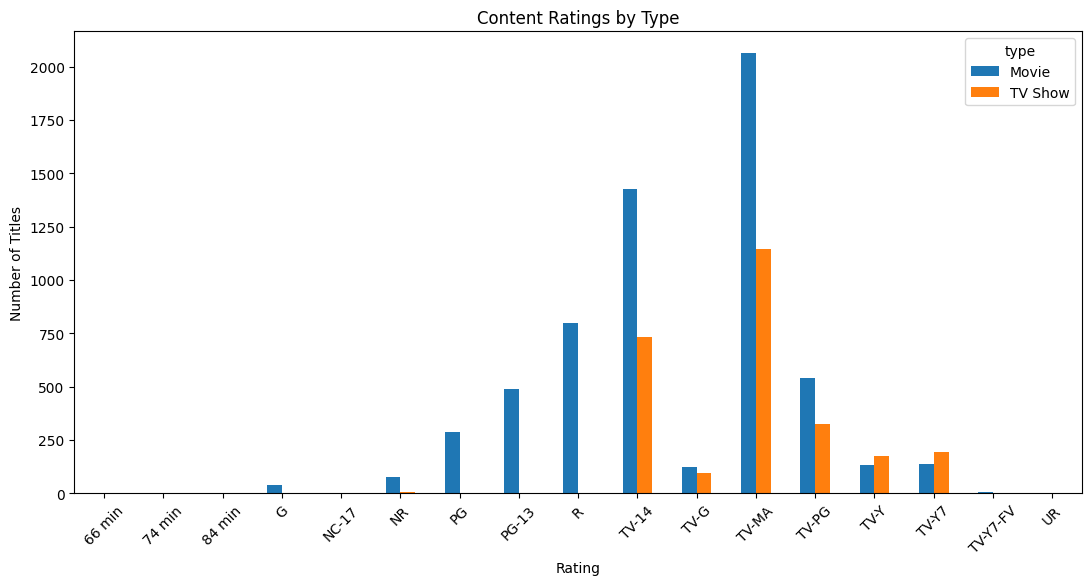

In [29]:
rating_type.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Content Ratings by Type')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

**Which countries have the highest content count by type?**

In [30]:
# Split multiple countries into separate rows

country_data = df_clean[
    df_clean['country'] != 'Unknown'
].copy()

country_data['country'] = country_data['country'].str.split(',')

country_data = country_data.explode('country')

country_data['country'] = country_data['country'].str.strip()

# Count countries by content type
top_countries = (
    country_data.groupby(['country', 'type'])
    .size()
    .reset_index(name='total_titles')
)

top_countries.head()

,country,type,total_titles
0,,Movie,6
1,,TV Show,1
2,Afghanistan,Movie,1
3,Albania,Movie,1
4,Algeria,Movie,3


**Find top 10 countries**

In [31]:
top_10_countries = (
    country_data['country']
    .value_counts()
    .head(10)
)

top_10_countries

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

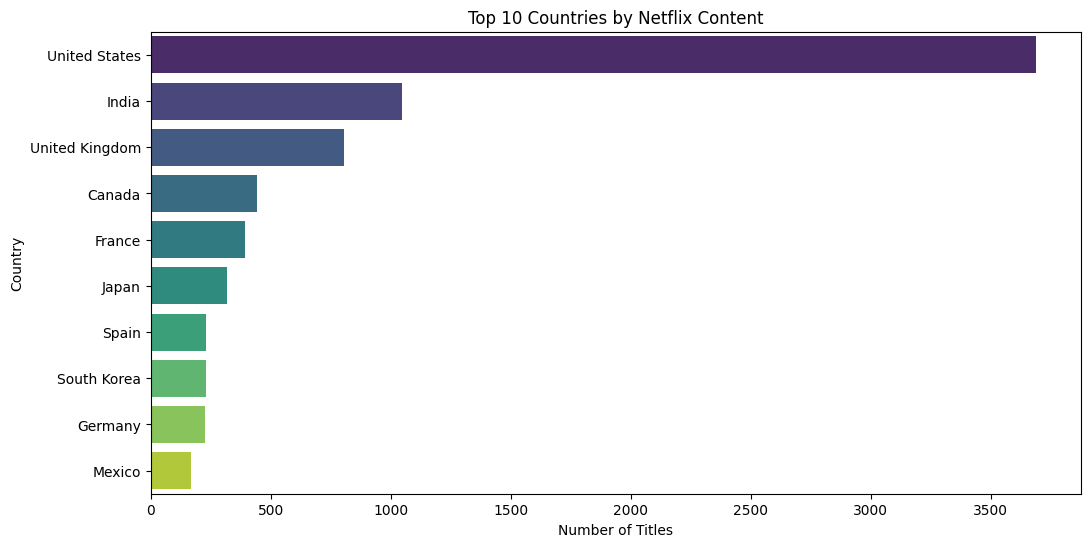

In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index,
    hue=top_10_countries.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

**What are the most common genres on Netflix?**

In [33]:
# Split genres into separate rows

genre_data = df_clean.copy()

genre_data['listed_in'] = genre_data['listed_in'].str.split(',')

genre_data = genre_data.explode('listed_in')

genre_data['listed_in'] = genre_data['listed_in'].str.strip()

# Count genres
genre_counts = genre_data['listed_in'].value_counts()

print(genre_counts.head(15))

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Crime TV Shows               470
Kids' TV                     451
Docuseries                   395
Name: count, dtype: int64


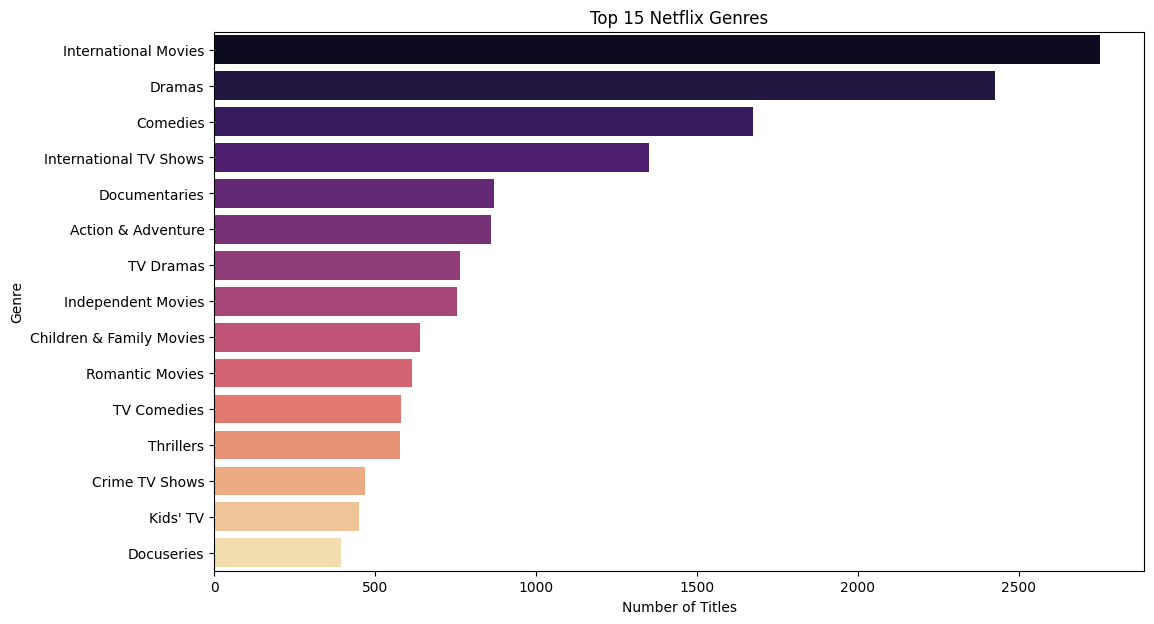

In [34]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=genre_counts.head(15).values,
    y=genre_counts.head(15).index,
    hue=genre_counts.head(15).index,
    palette='magma',
    legend=False
)

plt.title('Top 15 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

**Which year had the most content additions?**

In [35]:
# Extract year from date_added

df_clean['year_added'] = df_clean['date_added'].dt.year

# Count content additions by year

year_added_counts = (
    df_clean['year_added']
    .value_counts()
    .sort_index()
)

year_added_counts

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64

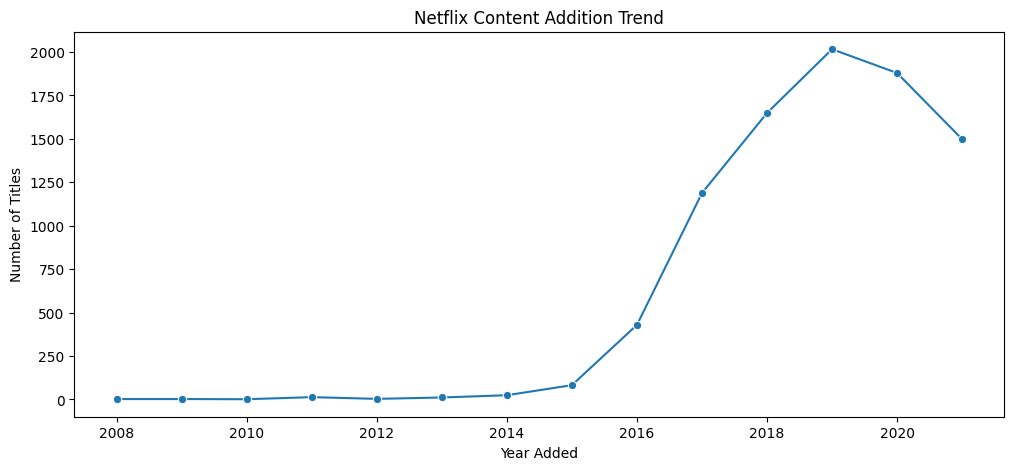

In [36]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=year_added_counts.index,
    y=year_added_counts.values,
    marker='o'
)

plt.title('Netflix Content Addition Trend')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')

plt.show()

**Verify the cleaned dataset**

In [37]:

# Check dataset information

print("Dataset Shape:", df.shape)

print("\nAvailable Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nContent Types:")
print(df["type"].value_counts())

print("\nContent Ratings:")
print(df["rating"].value_counts().head(10))


Dataset Shape: (8807, 12)

Available Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Content Types:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Content Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


**Prepare movie duration data**

In [38]:

# Filter only Movies
movie_data = df[df["type"] == "Movie"].copy()

# Extract numeric duration
movie_data["duration_numeric"] = (
    movie_data["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# Remove missing duration values
movie_duration = movie_data["duration_numeric"].dropna()

print("Total Movies:", len(movie_duration))
print(movie_duration.head())


Total Movies: 6128
0      90.0
6      91.0
7     125.0
9     104.0
12    127.0
Name: duration_numeric, dtype: float64


**Calculate descriptive statistics**

In [39]:

print("Mean Duration:", movie_duration.mean())
print("Median Duration:", movie_duration.median())
print("Standard Deviation:", movie_duration.std())
print("Minimum Duration:", movie_duration.min())
print("Maximum Duration:", movie_duration.max())

print("\nQuartiles:")
print(movie_duration.quantile([0.25, 0.50, 0.75]))


Mean Duration: 99.57718668407311
Median Duration: 98.0
Standard Deviation: 28.290593447417347
Minimum Duration: 3.0
Maximum Duration: 312.0

Quartiles:
0.25     87.0
0.50     98.0
0.75    114.0
Name: duration_numeric, dtype: float64


**Calculate Interquartile Range (IQR)**

In [40]:

Q1 = movie_duration.quantile(0.25)
Q3 = movie_duration.quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print(
    "Typical duration range:",
    Q1, "to", Q3, "minutes"
)


Q1: 87.0
Q3: 114.0
IQR: 27.0
Typical duration range: 87.0 to 114.0 minutes


**Visualize duration distribution**

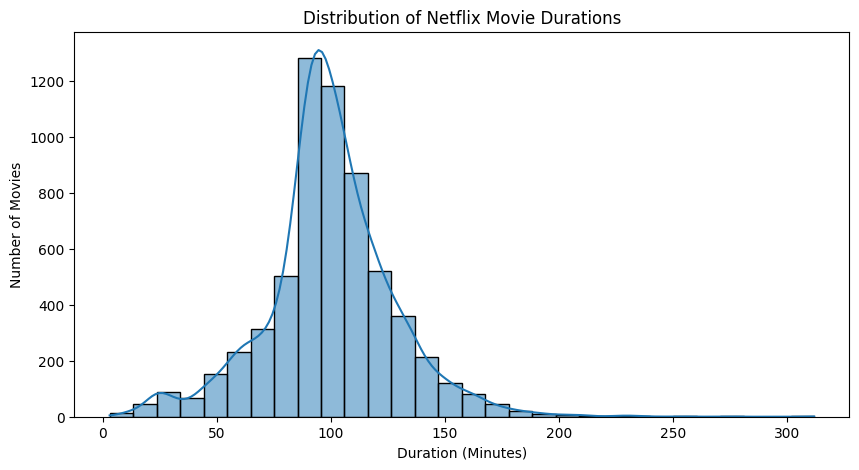

In [41]:

plt.figure(figsize=(10, 5))

sns.histplot(
    movie_duration,
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.show()


**Identify potential outliers**

In [42]:

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = movie_duration[
    (movie_duration < lower_limit) |
    (movie_duration > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Potential Outliers:", len(outliers))

print("\nOutlier Durations:")
print(outliers.sort_values().to_list()[:20])


Lower Limit: 46.5
Upper Limit: 154.5
Number of Potential Outliers: 450

Outlier Durations:
[3.0, 5.0, 8.0, 9.0, 10.0, 11.0, 11.0, 12.0, 12.0, 12.0, 13.0, 13.0, 13.0, 14.0, 14.0, 14.0, 15.0, 15.0, 15.0, 16.0]


**Boxplot**

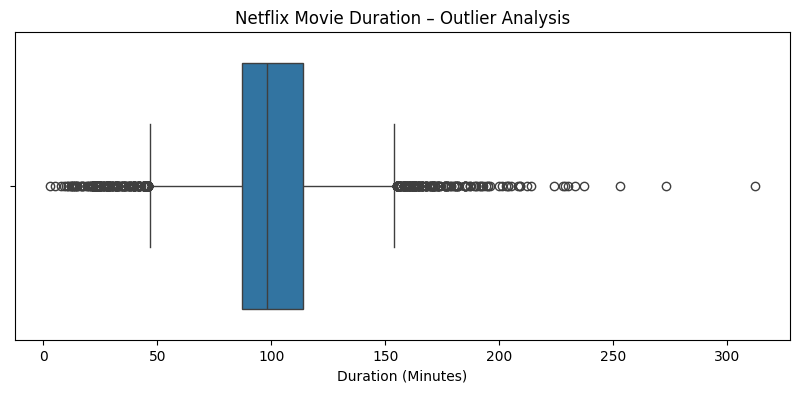

In [43]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=movie_duration)

plt.title("Netflix Movie Duration – Outlier Analysis")
plt.xlabel("Duration (Minutes)")
plt.show()
